In [2]:
# Install dependencies
%pip -q install \
    "transformers==4.57.1" \
    "accelerate==1.11.0" \
    "bitsandbytes==0.48.1" \
    "ultralytics==8.3.221" \
    "huggingface-hub==0.36.0" \
    "opencv-python==4.12.0.88" \
    "av==16.0.1" \
    matplotlib Pillow

import os
import gc
import re
import json
from pathlib import Path

os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

import av
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt

from PIL import Image, ImageOps, ImageDraw
from huggingface_hub import hf_hub_download
from ultralytics import YOLO

from transformers import (
    AutoProcessor,
    CLIPModel,
    Qwen3VLForConditionalGeneration,
    BitsAndBytesConfig,
)

# config

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

VLM_NAME = "Qwen/Qwen3-VL-8B-Instruct"
CLIP_NAME = "openai/clip-vit-base-patch32"

SAMPLE_FPS = 4.0
MAX_FRAMES = 240
TOP_K = 45
MAX_CLAIM_REGIONS = 2
DETECTION_CONF = 0.17

DETECTOR = None


def release_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


#  DAMAGE DETECTION

def load_detector():
    global DETECTOR

    if DETECTOR is None:
        weights = hf_hub_download(
            repo_id="abdullahg7/cardd-yolov8s",
            filename="v1.0/best.pt",
        )
        DETECTOR = YOLO(weights)

    return DETECTOR


def detect_damage(image):
    result = load_detector().predict(
        image,
        conf=DETECTION_CONF,
        imgsz=1024,
        device=DEVICE,
        verbose=False,
    )[0]

    detections = []

    for box, score, cls in zip(
        result.boxes.xyxy.cpu().numpy(),
        result.boxes.conf.cpu().numpy(),
        result.boxes.cls.cpu().numpy(),
    ):
        detections.append({
            "type": str(result.names[int(cls)]).lower(),
            "confidence": float(score),
            "box": box.tolist(),
        })

    return detections


def claim_types(claim):
    patterns = {
        "scratch": r"scratch|scrape|scuff",
        "dent": r"dent|ding",
        "crack": r"crack",
        "glass_shatter": r"shatter|broken glass",
        "lamp_broken": r"broken lamp|broken light",
    }

    return {
        name
        for name, pattern in patterns.items()
        if re.search(pattern, claim, re.I)
    }


def box_overlap(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = max(1, (a[2] - a[0]) * (a[3] - a[1]))
    area_b = max(1, (b[2] - b[0]) * (b[3] - b[1]))

    return intersection / min(area_a, area_b)


def claim_regions(detections, claim):
    allowed = claim_types(claim)

    candidates = sorted(
        [
            d for d in detections
            if not allowed or d["type"] in allowed
        ],
        key=lambda x: -x["confidence"],
    )

    regions = []

    for item in candidates:
        matched = None

        for region in regions:
            if box_overlap(
                region["box"],
                item["box"],
            ) > 0.35:
                matched = region
                break

        if matched is None:
            regions.append({
                "box": list(item["box"]),
                "detections": [item],
            })
        else:
            a = matched["box"]
            b = item["box"]

            matched["box"] = [
                min(a[0], b[0]),
                min(a[1], b[1]),
                max(a[2], b[2]),
                max(a[3], b[3]),
            ]

            matched["detections"].append(item)

    return regions[:MAX_CLAIM_REGIONS]


# IMAGE REGIONS

def polygon_from_box(box):
    x1, y1, x2, y2 = box

    return np.float32([
        [x1, y1],
        [x2, y1],
        [x2, y2],
        [x1, y2],
    ])


def crop_region(image, polygon, padding=0.18):
    points = np.asarray(polygon)

    x1, y1 = points.min(axis=0)
    x2, y2 = points.max(axis=0)

    dx = (x2 - x1) * padding
    dy = (y2 - y1) * padding

    bounds = [
        max(0, int(x1 - dx)),
        max(0, int(y1 - dy)),
        min(image.width, int(np.ceil(x2 + dx))),
        min(image.height, int(np.ceil(y2 + dy))),
    ]

    return image.crop(tuple(bounds)), bounds


def outline_region(image, polygon):
    output = image.copy()

    if polygon is None:
        return output

    points = [
        tuple(map(int, p))
        for p in polygon
    ]

    ImageDraw.Draw(output).line(
        points + [points[0]],
        fill="red",
        width=3,
    )

    return output


# VIDEO FRAME EXTRACTION

def extract_video_frames(path):
    frames = []

    with av.open(str(path)) as container:
        stream = container.streams.video[0]

        if stream.duration is not None:
            duration = float(
                stream.duration * stream.time_base
            )
        elif container.duration is not None:
            duration = float(
                container.duration / av.time_base
            )
        elif stream.frames and stream.average_rate:
            duration = stream.frames / float(stream.average_rate)
        else:
            duration = 0

        interval = max(
            1 / SAMPLE_FPS,
            duration / MAX_FRAMES,
        )

        next_time = 0.0
        first_time = None

        for frame in container.decode(stream):
            if frame.pts is None:
                continue

            absolute_time = float(
                frame.pts * frame.time_base
            )

            if first_time is None:
                first_time = absolute_time

            timestamp = absolute_time - first_time

            if timestamp + 1e-6 < next_time:
                continue

            image = frame.to_image().convert("RGB")

            if max(image.size) > 1600:
                image.thumbnail(
                    (1600, 1600),
                    Image.Resampling.LANCZOS,
                )

            frames.append({
                "time": float(timestamp),
                "image": image,
            })

            next_time = timestamp + interval

            if len(frames) >= MAX_FRAMES:
                break

    if not frames:
        raise ValueError(
            f"No video frames extracted: {path}"
        )

    return frames


# FRAME SIMILARITY

def image_embeddings(model, processor, images):
    vectors = []

    for start in range(0, len(images), 16):
        batch = [
            ImageOps.pad(
                image,
                (224, 224),
                color=(127, 127, 127),
            )
            for image in images[start:start + 16]
        ]

        inputs = processor(
            images=batch,
            return_tensors="pt",
        ).to(DEVICE)

        with torch.inference_mode():
            features = model.get_image_features(**inputs)

            if not isinstance(features, torch.Tensor):
                features = features.pooler_output

            features = torch.nn.functional.normalize(
                features.float(),
                dim=-1,
            )

        vectors.append(
            features.cpu().numpy()
        )

    return np.concatenate(vectors)


# 5. IMAGE ALIGNMENT

def extract_features(image, mask=None):
    gray = cv2.cvtColor(
        np.asarray(image),
        cv2.COLOR_RGB2GRAY,
    )

    scale = min(1.0, 1400 / max(image.size))

    if scale < 1:
        gray = cv2.resize(
            gray,
            None,
            fx=scale,
            fy=scale,
        )

    if mask is not None:
        mask = cv2.resize(
            mask,
            (gray.shape[1], gray.shape[0]),
            interpolation=cv2.INTER_NEAREST,
        )

    keypoints, descriptors = cv2.SIFT_create(
        nfeatures=4000
    ).detectAndCompute(gray, mask)

    points = np.float32([
        k.pt for k in keypoints
    ]).reshape(-1, 2) / scale

    return points, descriptors


def align_claim_region(
    source_features,
    frame_features,
    reference_box,
    frame_size,
):
    source_points, source_desc = source_features
    frame_points, frame_desc = frame_features

    if source_desc is None or frame_desc is None:
        return None

    if min(len(source_desc), len(frame_desc)) < 12:
        return None

    pairs = cv2.BFMatcher().knnMatch(
        source_desc,
        frame_desc,
        k=2,
    )

    good = [
        a
        for pair in pairs
        if len(pair) == 2
        for a, b in [pair]
        if a.distance < 0.75 * b.distance
    ]

    if len(good) < 12:
        return None

    src = np.float32([
        source_points[m.queryIdx]
        for m in good
    ])

    dst = np.float32([
        frame_points[m.trainIdx]
        for m in good
    ])

    H, inliers = cv2.findHomography(
        src,
        dst,
        cv2.RANSAC,
        4.0,
    )

    if H is None or inliers is None:
        return None

    if not np.isfinite(H).all():
        return None

    keep = inliers.ravel().astype(bool)
    count = int(keep.sum())

    if count < 12 or count / len(good) < 0.35:
        return None

    source_polygon = polygon_from_box(reference_box)

    projected = cv2.perspectiveTransform(
        source_polygon.reshape(-1, 1, 2),
        H,
    ).reshape(-1, 2)

    width, height = frame_size

    if not np.isfinite(projected).all():
        return None

    if not cv2.isContourConvex(projected):
        return None

    if (
        (projected[:, 0] < 0).any()
        or (projected[:, 0] >= width).any()
        or (projected[:, 1] < 0).any()
        or (projected[:, 1] >= height).any()
    ):
        return None

    area = abs(cv2.contourArea(projected))

    edges = np.linalg.norm(
        projected - np.roll(projected, 1, axis=0),
        axis=1,
    )

    if area < 700 or edges.min() < 18:
        return None

    source_area = abs(
        cv2.contourArea(source_polygon)
    )

    if (
        cv2.contourArea(source_polygon, oriented=True)
        * cv2.contourArea(projected, oriented=True)
        <= 0
    ):
        return None

    scale = np.sqrt(
        area / max(source_area, 1)
    )

    if scale < 0.15 or scale > 5:
        return None

    source_inliers = src[keep]

    hull = cv2.convexHull(source_inliers)

    coverage, _ = cv2.intersectConvexConvex(
        hull,
        source_polygon,
    )

    coverage /= max(source_area, 1)

    distance = cv2.pointPolygonTest(
        hull,
        tuple(map(float, source_polygon.mean(axis=0))),
        True,
    )

    diagonal = np.linalg.norm(
        source_polygon[2] - source_polygon[0]
    )

    if coverage < 0.15:
        return None

    if distance < -0.3 * diagonal:
        return None

    prediction = cv2.perspectiveTransform(
        source_inliers.reshape(-1, 1, 2),
        H,
    ).reshape(-1, 2)

    error = float(
        np.median(
            np.linalg.norm(
                prediction - dst[keep],
                axis=1,
            )
        )
    )

    if error > 5:
        return None

    score = count + coverage * 12 - error * 3

    return {
        "polygon": projected,
        "score": float(score),
    }


def find_best_frames(
    frames,
    similarities,
    company_features,
    company_box,
):
    ranked = np.argsort(
        -similarities
    )[:TOP_K].tolist()

    uniform = np.linspace(
        0,
        len(frames) - 1,
        min(25, len(frames)),
        dtype=int,
    ).tolist()

    candidates = []

    for index in dict.fromkeys(ranked + uniform):
        row = frames[index]

        alignment = align_claim_region(
            company_features,
            extract_features(row["image"]),
            company_box,
            row["image"].size,
        )

        if alignment is None:
            continue

        crop, _ = crop_region(
            row["image"],
            alignment["polygon"],
        )

        sharpness = float(
            cv2.Laplacian(
                cv2.cvtColor(
                    np.asarray(crop),
                    cv2.COLOR_RGB2GRAY,
                ),
                cv2.CV_64F,
            ).var()
        )

        ranking = (
            alignment["score"]
            + 5 * float(similarities[index])
            + min(sharpness / 75, 8)
        )

        candidates.append({
            **row,
            **alignment,
            "ranking": ranking,
        })

    candidates.sort(
        key=lambda x: -x["ranking"]
    )

    selected = []

    for candidate in candidates:
        if all(
            abs(candidate["time"] - previous["time"]) >= 0.4
            for previous in selected
        ):
            selected.append(candidate)

        if len(selected) == 2:
            break

    fallback = frames[
        int(np.argmax(similarities))
    ]

    return selected, fallback


# DETECTION CONFIDENCE

def best_region_detection(
    detections,
    polygon,
    allowed_types,
):
    box = [
        *polygon.min(axis=0),
        *polygon.max(axis=0),
    ]

    matches = []

    for item in detections:
        if (
            allowed_types
            and item["type"] not in allowed_types
        ):
            continue

        d = item["box"]

        center = (
            (d[0] + d[2]) / 2,
            (d[1] + d[3]) / 2,
        )

        inside = (
            cv2.pointPolygonTest(
                polygon,
                center,
                False,
            ) >= 0
        )

        overlap = box_overlap(box, d)

        if inside or overlap >= 0.28:
            matches.append(item)

    return max(
        matches,
        key=lambda x: x["confidence"],
        default=None,
    )


def region_confidences(
    image,
    polygon,
    allowed_types,
):
    full_result = best_region_detection(
        detect_damage(image),
        polygon,
        allowed_types,
    )

    crop, bounds = crop_region(
        image,
        polygon,
    )

    local_polygon = (
        polygon - np.float32(bounds[:2])
    )

    crop_result = best_region_detection(
        detect_damage(crop),
        local_polygon,
        allowed_types,
    )

    def clean(result):
        if result is None:
            return None

        return {
            "type": result["type"],
            "confidence": round(result["confidence"], 4),
        }

    return {
        "full_frame": clean(full_result),
        "zoom": clean(crop_result),
        "zoom_source_px": [crop.width, crop.height],
    }


def confidence_label(result):
    if result is None:
        return "not detected"

    return (
        f"{result['type']} "
        f"{result['confidence']:.3f}"
    )


# PAIRWISE VISION COMPARISON

PAIRWISE_SYSTEM = """
You examine photographic evidence in a vehicle rental dispute.

A renter recorded a car before taking possession and after returning it.
A rental company later supplied a photograph of alleged damage.

Your task is to compare specific visible physical marks.

You receive exactly TWO sources per comparison.
Each source contains:
1. An original full image showing the vehicle location.
2. A zoomed crop of that same location.

The red rectangle in the full image indicates location only.
It does not mean damage is present.

The zoomed crop has no red markings obscuring its pixels.

IMPORTANT:

Compare the actual physical marks, not merely vehicle location.

The same wheel arch, bumper shape, or fog lamp does not mean
that the same damage is present.

If the reference shows several obvious scratches and the
corresponding candidate surface is smooth, distinguish them.

Assess image quality relative to the size and contrast of the
reference marks. An image can be slightly soft yet adequate
to establish whether large visible scuffs are present.

Do not automatically classify an image as inadequate merely
because it is not perfectly sharp.

However, do not claim absence when the marks would be too
small or indistinct to resolve in the candidate.

Identify actual shapes, lines, positions, and differences.
Do not invent marks or transfer marks between images.

Do not infer who caused damage or legal responsibility.
"""


def clean_comparison_views(
    image,
    polygon,
    label,
):
    crop, _ = crop_region(
        image,
        polygon,
    )

    original_width = crop.width
    original_height = crop.height

    factor = min(
        3.0,
        512 / max(crop.size),
    )

    if factor > 1:
        crop = crop.resize(
            (
                round(crop.width * factor),
                round(crop.height * factor),
            ),
            Image.Resampling.BICUBIC,
        )

    return [
        {
            "type": "text",
            "text": (
                f"{label}: ORIGINAL FULL IMAGE. "
                "The outlined area identifies the region to compare."
            ),
        },
        {
            "type": "image",
            "image": outline_region(image, polygon),
        },
        {
            "type": "text",
            "text": (
                f"{label}: UNOBSTRUCTED ZOOMED CROP. "
                f"Original crop resolution: "
                f"{original_width}x{original_height} pixels. "
                "Inspect the actual surface and physical marks."
            ),
        },
        {
            "type": "image",
            "image": crop,
        },
    ]


def compare_image_pair(
    model,
    processor,
    reference_image,
    reference_polygon,
    candidate_image,
    candidate_polygon,
    reference_label,
    candidate_label,
):
    instruction = f"""
Compare two photographs of the corresponding vehicle location.

REFERENCE: {reference_label}
CANDIDATE: {candidate_label}

FIRST:
Identify the physical marks actually visible in REFERENCE.

SECOND:
Inspect the same vehicle location in CANDIDATE.

THIRD:
Determine whether the SPECIFIC reference marks are present
in CANDIDATE.

Use these definitions:

same:
The same distinctive physical marks can be identified,
with corresponding shape, orientation, and location.

absent:
The candidate clearly shows the relevant surface without
the reference marks. Its image quality is adequate to
determine whether marks of that size would be visible.

different:
Other physical marks exist, but they do not match
the specific reference damage.

unclear:
The specific mark cannot be confidently compared because
of insufficient detail, uncertain alignment, or ambiguity.

EXAMPLE OF THE VISUAL DISTINCTION:

If REFERENCE contains several dark curved scratches near
the wheel arch and CANDIDATE shows a smooth bumper in that
same location, those are different physical appearances.

You must independently establish whether that distinction
actually exists in THESE images.

Do not say "blurry" without considering whether the
specific reference marks are sufficiently large and
contrasting to be identifiable in the candidate.

Return ONLY this JSON object:

{{
 "reference_marks": "Describe visible reference marks",
 "candidate_marks": "Describe actual candidate surface",
 "candidate_location_visible": "yes|no|unclear",
 "candidate_detail_adequate": "yes|no",
 "match": "same|absent|different|unclear",
 "reason": "Brief specific visual comparison"
}}
"""

    content = [
        {
            "type": "text",
            "text": instruction,
        }
    ]

    content.extend(
        clean_comparison_views(
            reference_image,
            reference_polygon,
            reference_label,
        )
    )

    content.extend(
        clean_comparison_views(
            candidate_image,
            candidate_polygon,
            candidate_label,
        )
    )

    messages = [
        {
            "role": "system",
            "content": [
                {
                    "type": "text",
                    "text": PAIRWISE_SYSTEM,
                }
            ],
        },
        {
            "role": "user",
            "content": content,
        },
    ]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
        min_pixels=64 * 32 * 32,
        max_pixels=256 * 32 * 32,
    ).to(model.device)

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=350,
            do_sample=False,
        )

    response = processor.batch_decode(
        output[:, inputs.input_ids.shape[1]:],
        skip_special_tokens=True,
    )[0]

    del inputs, output

    start = response.find("{")
    end = response.rfind("}")

    if start < 0 or end < start:
        raise ValueError(
            "Visual model returned no valid comparison."
        )

    answer = json.loads(
        response[start:end + 1]
    )

    if answer.get("match") not in {
        "same", "absent", "different", "unclear"
    }:
        raise ValueError("Invalid visual match result.")

    if answer.get("candidate_location_visible") not in {
        "yes", "no", "unclear"
    }:
        raise ValueError("Invalid location assessment.")

    if answer.get("candidate_detail_adequate") not in {
        "yes", "no"
    }:
        raise ValueError("Invalid detail assessment.")

    for field in (
        "reference_marks",
        "candidate_marks",
        "reason",
    ):
        if (
            not isinstance(answer.get(field), str)
            or not answer[field].strip()
        ):
            raise ValueError(
                "Missing comparison explanation."
            )

    if (
        answer["candidate_location_visible"] != "yes"
        or answer["candidate_detail_adequate"] != "yes"
    ):
        answer["match"] = "unclear"

    return answer


# THREE CLAIM-SPECIFIC COMPARISONS

def verify_claim(
    model,
    processor,
    claim,
    company,
    target,
    before,
    after,
):
    company_polygon = polygon_from_box(
        target["box"]
    )

    # Comparison 1: Company vs AFTER
    print("Comparing company claim with AFTER...")

    company_after = compare_image_pair(
        model,
        processor,
        company,
        company_polygon,
        after["image"],
        after["polygon"],
        "COMPANY REFERENCE",
        f"AFTER RETURN {after['time']:.2f}s",
    )

    after_status = company_after["match"]
    before_status = "unclear"

    after_before = None
    company_before = None

    # Continue only when AFTER matches the company claim.
    if after_status == "same":

        # Comparison 2: AFTER vs BEFORE
        print("Comparing AFTER with BEFORE...")

        after_before = compare_image_pair(
            model,
            processor,
            after["image"],
            after["polygon"],
            before["image"],
            before["polygon"],
            f"AFTER RETURN {after['time']:.2f}s",
            f"BEFORE RENTAL {before['time']:.2f}s",
        )

        # Comparison 3: Company vs BEFORE
        print("Comparing company claim with BEFORE...")

        company_before = compare_image_pair(
            model,
            processor,
            company,
            company_polygon,
            before["image"],
            before["polygon"],
            "COMPANY REFERENCE",
            f"BEFORE RENTAL {before['time']:.2f}s",
        )

        first = after_before["match"]
        second = company_before["match"]

        if first == "same" and second == "same":
            before_status = "same"

        elif (
            first in {"absent", "different"}
            and second in {"absent", "different"}
        ):
            before_status = "absent"

    # Final verdict
    if (
        after_status == "same"
        and before_status == "same"
    ):
        verdict = "PRE-EXISTING DAMAGE"

    elif (
        after_status == "same"
        and before_status == "absent"
    ):
        verdict = "POSSIBLE NEW DAMAGE"

    else:
        verdict = "INCONCLUSIVE"

    return {
        "verdict": verdict,
        "before_status": before_status,
        "after_status": after_status,
        "company_description": company_after["reference_marks"],
        "before_description": (
            company_before["candidate_marks"]
            if company_before
            else "Not established"
        ),
        "after_description": company_after["candidate_marks"],
        "comparison": (
            company_before["reason"]
            if company_before
            else company_after["reason"]
        ),
        "checks": {
            "company_vs_after": company_after,
            "after_vs_before": after_before,
            "company_vs_before": company_before,
        },
    }


def compatible_observations(a, b):
    if a == "unclear" or b == "unclear":
        return True

    if a == b:
        return True

    if (
        a in {"absent", "different"}
        and b in {"absent", "different"}
    ):
        return True

    return False


# 9. MATPLOTLIB EVIDENCE

def show_evidence(
    company,
    target,
    before,
    after,
    before_fallback,
    after_fallback,
    output_path,
    show=True,
):
    entries = [
        (
            "COMPANY CLAIM",
            company,
            polygon_from_box(target["box"]),
            target["scores"],
            None,
        ),
        (
            "BEFORE RENTAL",
            before["image"] if before else before_fallback["image"],
            before["polygon"] if before else None,
            before["scores"] if before else None,
            before["time"] if before else before_fallback["time"],
        ),
        (
            "AFTER RETURN",
            after["image"] if after else after_fallback["image"],
            after["polygon"] if after else None,
            after["scores"] if after else None,
            after["time"] if after else after_fallback["time"],
        ),
    ]

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(15, 8),
    )

    for col, (label, image, poly, scores, timestamp) in enumerate(entries):

        title = label

        if timestamp is not None:
            title += f" ({timestamp:.2f}s)"

        axes[0, col].imshow(
            outline_region(image, poly)
        )

        axes[0, col].set_title(title)

        axes[0, col].axis("off")

        if poly is None:
            axes[1, col].text(
                0.5,
                0.5,
                "Matching location not found",
                ha="center",
                va="center",
                transform=axes[1, col].transAxes,
            )

        else:
            crop, _ = crop_region(
                image,
                poly,
            )

            # Unobstructed zoomed image
            axes[1, col].imshow(crop)

            full_score = confidence_label(
                scores["full_frame"]
            )

            zoom_score = confidence_label(
                scores["zoom"]
            )

            axes[1, col].set_title(
                f"Full frame: {full_score}\n"
                f"Zoom: {zoom_score} "
                f"({crop.width}×{crop.height}px)",
                fontsize=10,
            )

        axes[1, col].axis("off")

    fig.tight_layout()

    fig.savefig(
        output_path,
        dpi=160,
        bbox_inches="tight",
    )

    if show:
        plt.show()

    plt.close(fig)


# 10. SAVE IMAGES FOR FRONTEND

def save_evidence_images(
    folder,
    company,
    target,
    before,
    after,
):
    assets = {}

    entries = [
        (
            "company",
            company,
            polygon_from_box(target["box"]),
        ),
        (
            "before",
            before["image"] if before else None,
            before["polygon"] if before else None,
        ),
        (
            "after",
            after["image"] if after else None,
            after["polygon"] if after else None,
        ),
    ]

    for phase, image, poly in entries:
        if image is None:
            assets[phase] = None
            continue

        wide_path = folder / f"{phase}_frame.png"
        crop_path = folder / f"{phase}_crop.png"

        outline_region(
            image,
            poly,
        ).save(wide_path)

        crop_region(
            image,
            poly,
        )[0].save(crop_path)

        assets[phase] = {
            "frame": str(wide_path),
            "crop": str(crop_path),
        }

    return assets


# engine

def run_notmydent(
    claim_photo,
    before_path,
    after_path,
    claim,
    output_dir="notmydent_results",
    show=True,
):
    """
    Reusable backend entry point.

    Inputs:
        claim_photo: Company image path
        before_path: BEFORE video path
        after_path: AFTER video path
        claim: Written damage claim

    Returns:
        JSON-serializable results.

    show=True:
        Display Matplotlib comparison.

    show=False:
        Suitable for backend/API calls.
    """

    if not torch.cuda.is_available():
        raise RuntimeError(
            "CUDA GPU required for Qwen3-VL-8B."
        )

    for label, path in [
        ("Company image", claim_photo),
        ("BEFORE video", before_path),
        ("AFTER video", after_path),
    ]:
        if not Path(path).is_file():
            raise FileNotFoundError(
                f"Missing {label}: {path}"
            )

    if not claim.strip():
        raise ValueError(
            "Damage claim cannot be empty."
        )

    output_dir = Path(output_dir).resolve()
    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )



    print("Locating claimed damage...")

    company = ImageOps.exif_transpose(
        Image.open(claim_photo)
    ).convert("RGB")

    company_detections = detect_damage(
        company
    )

    targets = claim_regions(
        company_detections,
        claim,
    )

    response = {
        "claim": claim,
        "overall_verdict": "INCONCLUSIVE",
        "findings": [],
    }

    if not targets:
        response["message"] = (
            "Could not locate the claimed damage "
            "in the company image."
        )
        return response


    print("Reading BEFORE video...")
    before_frames = extract_video_frames(
        before_path
    )

    print("Reading AFTER video...")
    after_frames = extract_video_frames(
        after_path
    )

    videos = {
        "before": before_frames,
        "after": after_frames,
    }



    print("Finding corresponding vehicle locations...")

    clip_processor = AutoProcessor.from_pretrained(
        CLIP_NAME
    )

    clip_model = CLIPModel.from_pretrained(
        CLIP_NAME
    ).to(DEVICE).eval()

    frame_vectors = {}

    for phase, frames in videos.items():
        frame_vectors[phase] = image_embeddings(
            clip_model,
            clip_processor,
            [row["image"] for row in frames],
        )

    searches = []

    for target in targets:
        box = target["box"]

        company_crop, _ = crop_region(
            company,
            polygon_from_box(box),
            padding=1.0,
        )

        queries = image_embeddings(
            clip_model,
            clip_processor,
            [company, company_crop],
        )

        # Use surrounding landmarks for alignment.
        mask = np.full(
            (company.height, company.width),
            255,
            dtype=np.uint8,
        )

        x1, y1, x2, y2 = map(int, box)

        mask[
            max(0, y1):min(company.height, y2),
            max(0, x1):min(company.width, x2),
        ] = 0

        company_features = extract_features(
            company,
            mask,
        )

        if (
            company_features[1] is None
            or len(company_features[0]) < 12
        ):
            company_features = extract_features(company)

        selected = {}

        for phase in ("before", "after"):
            similarities = (
                frame_vectors[phase] @ queries.T
            ).max(axis=1)

            selected[phase] = find_best_frames(
                videos[phase],
                similarities,
                company_features,
                box,
            )

        searches.append({
            "target": target,
            "selected": selected,
        })

    del clip_model
    del clip_processor
    del frame_vectors

    release_gpu()



    allowed_types = claim_types(claim)

    for search in searches:
        target = search["target"]

        target["scores"] = region_confidences(
            company,
            polygon_from_box(target["box"]),
            allowed_types,
        )

        for phase in ("before", "after"):
            candidates, _ = search["selected"][phase]

            for candidate in candidates:
                candidate["scores"] = region_confidences(
                    candidate["image"],
                    candidate["polygon"],
                    allowed_types,
                )

    # Move detector away from GPU.
    if DETECTOR is not None:
        DETECTOR.to("cpu")

    release_gpu()



    needs_model = any(
        search["selected"]["before"][0]
        and search["selected"]["after"][0]
        for search in searches
    )

    model = None
    processor = None

    if needs_model:
        print("Loading visual comparison model...")

        quantization = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True,
            bnb_4bit_compute_dtype=torch.float16,
            llm_int8_skip_modules=[
                "model.visual",
                "lm_head",
            ],
        )

        model = Qwen3VLForConditionalGeneration.from_pretrained(
            VLM_NAME,
            quantization_config=quantization,
            dtype=torch.float16,
            device_map={"": 0},
            attn_implementation="sdpa",
        ).eval()

        processor = AutoProcessor.from_pretrained(
            VLM_NAME
        )


    try:
        for index, search in enumerate(
            searches,
            start=1,
        ):
            target = search["target"]

            before_candidates, before_fallback = (
                search["selected"]["before"]
            )

            after_candidates, after_fallback = (
                search["selected"]["after"]
            )

            before = (
                before_candidates[0]
                if before_candidates
                else None
            )

            after = (
                after_candidates[0]
                if after_candidates
                else None
            )

            assessment = {
                "verdict": "INCONCLUSIVE",
                "before_status": "unclear",
                "after_status": "unclear",
                "company_description": (
                    "Claimed region identified."
                ),
                "before_description": (
                    "No reliable matching location."
                ),
                "after_description": (
                    "No reliable matching location."
                ),
                "comparison": (
                    "Insufficient comparable evidence."
                ),
                "checks": {},
            }

            if before is not None and after is not None:
                try:
                    print(
                        f"Inspecting claimed area {index}..."
                    )

                    assessment = verify_claim(
                        model,
                        processor,
                        claim,
                        company,
                        target,
                        before,
                        after,
                    )

                    # Try an alternative frame if inconclusive.
                    if (
                        assessment["verdict"] == "INCONCLUSIVE"
                        and (
                            len(before_candidates) > 1
                            or len(after_candidates) > 1
                        )
                    ):
                        alternative_before = (
                            before_candidates[1]
                            if len(before_candidates) > 1
                            else before
                        )

                        alternative_after = (
                            after_candidates[1]
                            if len(after_candidates) > 1
                            else after
                        )

                        alternative = verify_claim(
                            model,
                            processor,
                            claim,
                            company,
                            target,
                            alternative_before,
                            alternative_after,
                        )

                        if (
                            alternative["verdict"] != "INCONCLUSIVE"
                            and compatible_observations(
                                assessment["before_status"],
                                alternative["before_status"],
                            )
                            and compatible_observations(
                                assessment["after_status"],
                                alternative["after_status"],
                            )
                        ):
                            before = alternative_before
                            after = alternative_after
                            assessment = alternative

                except Exception as error:
                    assessment["comparison"] = (
                        "Visual comparison failed: "
                        + str(error)
                    )


            folder = output_dir / f"claim_{index:02d}"
            folder.mkdir(
                parents=True,
                exist_ok=True,
            )

            figure_path = folder / "comparison.png"

            show_evidence(
                company,
                target,
                before,
                after,
                before_fallback,
                after_fallback,
                figure_path,
                show=show,
            )

            image_paths = save_evidence_images(
                folder,
                company,
                target,
                before,
                after,
            )

            finding = {
                "claim_id": f"claim_{index:02d}",
                "verdict": assessment["verdict"],

                "company": {
                    "description": assessment["company_description"],
                    "confidence": target["scores"],
                    "images": image_paths["company"],
                },

                "before": {
                    "timestamp_seconds": (
                        round(before["time"], 3)
                        if before else None
                    ),
                    "status": assessment["before_status"],
                    "description": assessment["before_description"],
                    "confidence": (
                        before["scores"]
                        if before else None
                    ),
                    "images": image_paths["before"],
                },

                "after": {
                    "timestamp_seconds": (
                        round(after["time"], 3)
                        if after else None
                    ),
                    "status": assessment["after_status"],
                    "description": assessment["after_description"],
                    "confidence": (
                        after["scores"]
                        if after else None
                    ),
                    "images": image_paths["after"],
                },

                "comparison": assessment["comparison"],
                "figure_path": str(figure_path),
                "comparisons": assessment["checks"],
            }

            response["findings"].append(finding)

    finally:
        del model
        del processor
        release_gpu()



    verdicts = {
        finding["verdict"]
        for finding in response["findings"]
    }

    if len(verdicts) == 1:
        response["overall_verdict"] = next(iter(verdicts))

    return response


print("NotMyDent engine ready.")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
NotMyDent engine ready.


In [3]:
from google.colab import files
from pathlib import Path


def get_file(label, variable, keywords, extensions):
    existing = globals().get(variable)

    if existing and Path(existing).is_file():
        print(f"{label}: Using {Path(existing).name}")
        return str(existing)

    candidates = [
        p for p in Path("/content").iterdir()
        if p.is_file()
        and p.suffix.lower() in extensions
        and any(word in p.stem.lower() for word in keywords)
    ]

    if len(candidates) == 1:
        print(f"{label}: Using {candidates[0].name}")
        return str(candidates[0])

    if len(candidates) > 1:
        print(f"\n{label}")

        for i, path in enumerate(candidates, 1):
            print(f"{i}. {path.name}")

        choice = int(input("Select file number: "))

        if not 1 <= choice <= len(candidates):
            raise ValueError("Invalid selection.")

        return str(candidates[choice - 1])

    print(f"\n{label}")
    uploaded = files.upload()

    if len(uploaded) != 1:
        raise ValueError("Upload exactly one file.")

    path = Path("/content") / next(iter(uploaded))

    if path.suffix.lower() not in extensions:
        raise ValueError("Unsupported file format.")

    return str(path)


BEFORE_VIDEO = get_file(
    "1. Upload BEFORE rental video",
    "BEFORE_VIDEO",
    ["before"],
    {".mp4", ".mov", ".mkv", ".avi"},
)

AFTER_VIDEO = get_file(
    "2. Upload AFTER return video",
    "AFTER_VIDEO",
    ["after"],
    {".mp4", ".mov", ".mkv", ".avi"},
)

COMPANY_PHOTO = get_file(
    "3. Upload COMPANY claim image",
    "COMPANY_PHOTO",
    ["claim", "damage", "dent", "scratch", "company"],
    {".jpg", ".jpeg", ".png", ".webp"},
)

CLAIM_TEXT = input(
    "\n4. What damage is the company claiming? "
).strip()

if not CLAIM_TEXT:
    raise ValueError("Please enter the damage claim.")

print("\nAll inputs ready.")


1. Upload BEFORE rental video


Saving before.mp4 to before.mp4

2. Upload AFTER return video


Saving after.mp4 to after.mp4

3. Upload COMPANY claim image


Saving dent.png to dent.png

4. What damage is the company claiming? there are some scratch on front of the car bumpers

All inputs ready.


Locating claimed damage...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


v1.0/best.pt:   0%|          | 0.00/22.5M [00:00<?, ?B/s]

Reading BEFORE video...
Reading AFTER video...
Finding corresponding vehicle locations...


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

...

chat_template.json: 0.00B [00:00, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Inspecting claimed area 1...
Comparing company claim with AFTER...


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Comparing AFTER with BEFORE...
Comparing company claim with BEFORE...


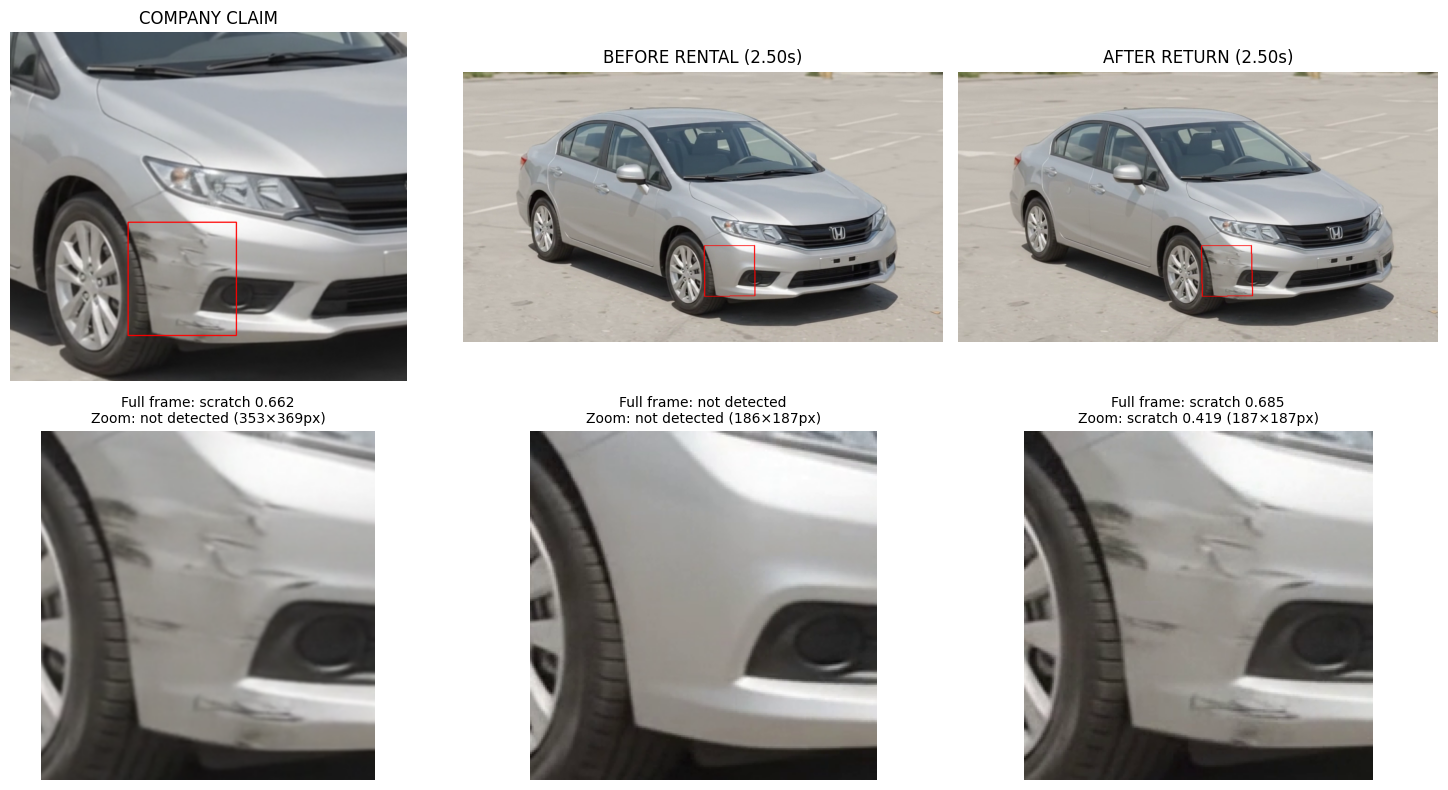


NOTMYDENT — FINAL ASSESSMENT

COMPANY CLAIM: there are some scratch on front of the car bumpers

CLAIMED AREA: claim_01

COMPANY REFERENCE:
Multiple dark, curved scratches and scuffs along the front fender, just above the wheel arch and below the headlight. A distinct horizontal dent is visible near the lower edge of the fender.

BEFORE RENTAL: 2.5 seconds
Smooth, unblemished surface with no visible scratches, dents, or scuffs in the same location.

AFTER RETURN: 2.5 seconds
Multiple dark, curved scratches and scuffs along the front fender, just above the wheel arch and below the headlight. A distinct horizontal dent is visible near the lower edge of the fender.

COMPARISON:
The reference shows multiple distinct scratches and scuffs in the bumper area, while the candidate image clearly shows a smooth surface in the identical location with no corresponding marks visible.

VERDICT: POSSIBLE NEW DAMAGE

OVERALL CONCLUSION: POSSIBLE NEW DAMAGE
The claimed damage matches the AFTER evidence

In [4]:
RESULTS = run_notmydent(
    claim_photo=COMPANY_PHOTO,
    before_path=BEFORE_VIDEO,
    after_path=AFTER_VIDEO,
    claim=CLAIM_TEXT,
    output_dir="/content/notmydent_results",
    show=True,
)


print("\n" + "=" * 60)
print("NOTMYDENT — FINAL ASSESSMENT")
print("=" * 60)

print("\nCOMPANY CLAIM:", RESULTS["claim"])

for finding in RESULTS["findings"]:

    print(f"\nCLAIMED AREA: {finding['claim_id']}")

    print("\nCOMPANY REFERENCE:")
    print(finding["company"]["description"])

    before = finding["before"]

    print(
        "\nBEFORE RENTAL:",
        before["timestamp_seconds"],
        "seconds",
    )
    print(before["description"])

    after = finding["after"]

    print(
        "\nAFTER RETURN:",
        after["timestamp_seconds"],
        "seconds",
    )
    print(after["description"])

    print("\nCOMPARISON:")
    print(finding["comparison"])

    print("\nVERDICT:", finding["verdict"])


print("\n" + "=" * 60)
print("OVERALL CONCLUSION:", RESULTS["overall_verdict"])
print("=" * 60)

if RESULTS["overall_verdict"] == "PRE-EXISTING DAMAGE":
    print(
        "The matching claimed damage was visible before "
        "the rental and after return. "
        "The evidence supports disputing the charge."
    )

elif RESULTS["overall_verdict"] == "POSSIBLE NEW DAMAGE":
    print(
        "The claimed damage matches the AFTER evidence "
        "but was not identifiable in the adequately "
        "inspected BEFORE location. "
        "This is consistent with possible new damage."
    )

else:
    print(
        "The available evidence does not establish "
        "a reliable conclusion for the complete claim."
    )